# Can a Machine Tell If My Tuition Was Worth It?
Classifying High School and University Writing Using Machine Learning

### 1. Introduction

Halfway through my fourth year of university education and countless "word counts" later, I would like to believe that my writing has improved. But can this change actually be detected, or does my writing still look largely the same? This project investigates that question as a binary classication problem: given a 200-word excerpt from one of my past assignments, can a model predict whether I wrote it in high school (0) or at university (1)? 

It's relevant to note that successfully identifying when a passage was written would not necessarily mean that my writing has improved.

Github link: https://github.com/mariasousa382/CS156-Machine-Learning-Maria.git

## Project Pipeline Overview

![Machine Learning Pipeline](../images/canva_diagram.png)

Overview of the machine learning pipeline, from collecting writing samples to comparing classification models and evaluating performance on a test set.


### 2. Dataset Collection

I faced the trauma of reopening my Google Classroom and started constructing a dataset from my personal archive of high school and university assignments. I cringed at times, had jumpscares at others, but eventually managed to select 22 assignments, evenly divided between the 2 educatoinal stages. I extracted three approximately 200-word passages from each, resulting in a total of 66 text samples. 

To make the samples more comparable and avoid obvious clues about their origin, I did not include introductory sections and removed all in-text citations. I also selected writing from three broad subject categories: biology/science, social research, and literature. The first two categories mostly consist of research-oriented academic writing, while the literature category includes both literary analysis and more creative writing. These are also balanced across the 2 classes, reducing the risk of the models simply associating certain subjects with an educational stage.

However, the dataset remains relatively small, and that the three passages extracted from each assignment are not fully independent observations. Considering I'm a CS major, it doesn't come as a surprise that finding university assignments covering topics similar to those I studied in high school was difficult. Even seemingly comparable courses, such as my high school philosophy class and AH111, proved unhelpful, since my high school philosophy assignments are all in Portuguese... 

Another limitation is the uneven distribution of assignments across time. Most samples come from my last two years of high school and the freshman year of university, when we were covering broader topics, which are not very far apart. I did, however, make an effort to include assignments from concentration courses taken in later years to better represent my university writing.

Overall, I matched the assignments as closely as I could, and I believe the topics are reasonably well balanced. 

### 3. Exploratory Data Analysis 

In [ ]:
# Imports

# data manipulation and numerical operations
import pandas as pd
import numpy as np
import re

# data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# model selection and cross-validation
from sklearn.model_selection import (
    train_test_split,
    StratifiedGroupKFold,
    cross_validate,
    cross_val_predict
)

# preprocessing and feature extraction
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer

# machine learning models
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB

# machine learning pipelines
from sklearn.pipeline import make_pipeline

# model evaluation
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


#### 3.1 Dataset Inspection

Before preprocessing the text, I inspected the dataset's structure, descriptive statistics, and potential data-quality issues. In particular, I checked for missing values, duplicate passages, consistent labeling, and whether each assignment contributed exactly three samples.

In [81]:
# load the dataset
df = pd.read_csv("../data/assignments.csv")

# look at the first five rows
display(df.head())

# dataset information (dimensions, data types, missing values)
df.info()

# descriptive statistics
display(df.describe(include="all"))

# check duplicate texts
print("Duplicate texts:", df["text"].duplicated().sum())

,assignment_id,chunk_id,text,year,subject,class,label
0,1,1,while\nlustre is determined by an interaction ...,4,bio,ns144,1
1,1,2,The narrow-sense heritability of literary prod...,4,bio,ns144,1
2,1,3,I know nothing about prions yet I’ve heard whi...,4,bio,ns144,1
3,2,1,The amount of samples in our experiment direct...,3,bio,apbio,0
4,2,2,"In general, as observed in Table 1, samples wi...",3,bio,apbio,0


<class 'pandas.DataFrame'>
RangeIndex: 66 entries, 0 to 65
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   assignment_id  66 non-null     int64
 1   chunk_id       66 non-null     int64
 2   text           66 non-null     str  
 3   year           66 non-null     int64
 4   subject        66 non-null     str  
 5   class          66 non-null     str  
 6   label          66 non-null     int64
dtypes: int64(4), str(3)
memory usage: 3.7 KB


,assignment_id,chunk_id,text,year,subject,class,label
count,66.000000,66.000000,66,66.000000,66,66,66.000000
unique,NaN,NaN,66,NaN,3,14,NaN
top,NaN,NaN,while\nlustre is determined by an interaction ...,NaN,social,english,NaN
freq,NaN,NaN,1,NaN,36,9,NaN
mean,11.500000,2.000000,NaN,2.318182,NaN,NaN,0.500000
std,6.392905,0.822753,NaN,0.979153,NaN,NaN,0.503831
min,1.000000,1.000000,NaN,1.000000,NaN,NaN,0.000000
25%,6.000000,1.000000,NaN,1.000000,NaN,NaN,0.000000
50%,11.500000,2.000000,NaN,2.500000,NaN,NaN,0.500000
75%,17.000000,3.000000,NaN,3.000000,NaN,NaN,1.000000


Duplicate texts: 0


In [82]:
# count passages belonging to each educational level
print("Samples per label:")
print(df["label"].value_counts().sort_index())

# count distinct assignments belonging to each educational level
print("\nAssignments per label:")
print(df.groupby("label")["assignment_id"].nunique())

# check whether each assignment contains exactly three passages
print("\nThree passages per assignment:", df.groupby("assignment_id").size().eq(3).all())

# check that assignment and chunk identifiers uniquely identify each passage
print("Unique assignment/chunk pairs:", not df.duplicated(subset=["assignment_id", "chunk_id"]).any())


Samples per label:
label
0    33
1    33
Name: count, dtype: int64

Assignments per label:
label
0    11
1    11
Name: assignment_id, dtype: int64

Three passages per assignment: True
Unique assignment/chunk pairs: True


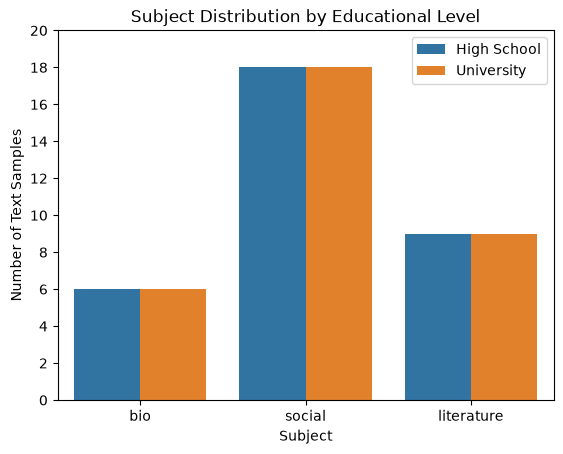

In [83]:
# compare subject distribution across educational levels
sns.countplot(data=df, x="subject", hue="label")  # count samples per subject, grouped by label

plt.title("Subject Distribution by Educational Level")
plt.xlabel("Subject")  
plt.ylabel("Number of Text Samples") 
plt.yticks(range(0, 21, 2)) 
plt.legend(labels=["High School", "University"])
plt.show()  

The dataset contains 33 passages from each educational level, with identical distributions across the three broad subject categories: 6 biology, 18 social research, and 9 literature passages per group. 

#### 3.2 Text Cleaning

Since the writing samples were collected from different assignments and document formats, I standardized minor formatting inconsistencies including normalizing whitespace, removed invisible characters, and standardized different representations of dashes and quotation marks.

I avoided removing punctuation, capitalization, or stopwords altogether since these could contain useful information about differences in my writing style. I also kept the original text in a separate column so that I could compare the original and cleaned versions.

In [99]:

# adapted from Python's official re and unicodedata documentation
def clean_text(text):
    text = unicodedata.normalize("NFC", text)  # standardize Unicode encoding
    text = text.replace("\u00a0", " ") # replace nonbreaking spaces
    text = text.replace("\u200b", "") # Remove invisible zero-width spaces

    text = text.replace("–", "-").replace("—", "-") # standardize dashes
    text = text.replace("“", '"').replace("”", '"') # standardize double quotes
    text = text.replace("‘", "'").replace("’", "'") # standardize apostrophes

    text = re.sub(r"\s+", " ", text)  # replace repeated spaces, tabs, and line breaks
    return text.strip() # remove leading and trailing whitespace

# preserve original text and create a cleaned version
df["clean_text"] = df["text"].apply(clean_text)

# compare original and cleaned text
print("Original:\n", repr(df["text"].iloc[0][:300]))
print("\nCleaned:\n", repr(df["clean_text"].iloc[0][:300]))

# count passages modified by cleaning
changed = (df["text"] != df["clean_text"]).sum()
print(f"Modified passages: {changed}/{len(df)}")


Original:
 'while\nlustre is determined by an interaction between the genotype and the environment. Humidity could affect\nthe expression or activity of genes involved in pigment production, and the 2 genotypes respond\ndifferently to this environmental signal. For instance, G1 and G2 could encode different versio'

Cleaned:
 'while lustre is determined by an interaction between the genotype and the environment. Humidity could affect the expression or activity of genes involved in pigment production, and the 2 genotypes respond differently to this environmental signal. For instance, G1 and G2 could encode different versio'
Modified passages: 64/66


#### 3.3 Passage Length Standardization

Since the classification task is based on 200-word excerpts, I checked the length of each passage to identify inconsistencies. Of the 66 samples, 61 contained exactly 200 words, four contained between 201 and 204 words, and one had 300 words (oopsies). I standardized by removing excess words from the end. 

In [100]:
# count words in each cleaned passage
df["word_count"] = df["clean_text"].str.split().str.len()
display(df["word_count"].describe()) # word count statistic 
print("Exactly 200 words:", (df["word_count"] == 200).sum()) # how many passages contain exactly 200 words

# show passages that differ from 200 words
display(df.loc[df["word_count"] != 200, ["assignment_id", "chunk_id", "label", "word_count"]])

count     66.000000
mean     201.681818
std       12.310295
min      200.000000
25%      200.000000
50%      200.000000
75%      200.000000
max      300.000000
Name: word_count, dtype: float64

Exactly 200 words: 61


,assignment_id,chunk_id,label,word_count
20,7,3,0,201
54,19,1,1,204
55,19,2,1,204
56,19,3,1,202
64,22,2,0,300


In [86]:
# trim each passage to exactly 200 words
df["clean_text"] = df["clean_text"].apply(lambda text: " ".join(text.split()[:200]))

# update word counts
df["word_count"] = df["clean_text"].str.split().str.len()

# verify that all passages contain exactly 200 words
print("All passages have 200 words:", (df["word_count"] == 200).all())

All passages have 200 words: True


#### 3.4 Linguistic Feature Exploration

Now I'll extracted several linguistic features including average word length, vocabulary diversity (proportion of unique words in a passage), and average sentence length. These features provide interpretable measurements of writing style. I first examine their distributions across educational levels to see whether any differences are apparent before training the classification models.

In [87]:
# Chat GPT generate code

# calculate average word length 
# split into words, strop punctation, count the characters in each word, sum the lengths, and divide by the number of words
df["avg_word_length"] = df["clean_text"].apply(
    lambda text: sum(len(word.strip(".,!?;:\"'()")) for word in text.split()) / len(text.split())
)

# calculate vocabulary diversity as the proportion of unique words
# convert to lowercase (so that "The" and "the" are counted as the same word)
# find the substrings matching the pattern for words (\b\w+\b)
# calculate ration of unique words (set) to total words
df["vocab_diversity"] = df["clean_text"].apply(
    lambda text: len(set(re.findall(r"\b\w+\b", text.lower()))) /
                 len(re.findall(r"\b\w+\b", text.lower())))

# calculate average sentence length using complete sentences only
def avg_sentence_length(text):
    # extract segments ending with a period, question mark, or exclamation mark
    sentences = re.findall(r"[^.!?]+[.!?]+", text)

    # exclude the first segment if the passage begins mid-sentence
    if sentences and text[:1].islower():
        sentences = sentences[1:]

    # calculate word counts for the remaining sentences
    lengths = [len(sentence.split()) for sentence in sentences]

    # return the average 
    return sum(lengths) / len(lengths) if lengths else float("nan")

df["avg_sentence_length"] = df["clean_text"].apply(avg_sentence_length) # apply the function to passages

# compare average feature values by educational level
features = ["avg_word_length", "vocab_diversity", "avg_sentence_length"]
display(df.groupby("label")[features].agg(["mean", "std"]).round(3))


avg_word_length        vocab_diversity        avg_sentence_length       
                 mean    std            mean    std                mean    std
label                                                                         
0               5.222  0.532           0.624  0.084              22.663  6.245
1               5.478  0.476           0.642  0.056              23.076  5.786

The results suggest that my writing has remained surprisingly consistent between high school and university, at least according to these basic linguistic measurements. University passages contain slightly longer words on average (5.48 versus 5.22) and slightly higher vocabulary diversity (0.642 versus 0.624). Average sentence length is also remarkably similar. 

Interestingly, the differences between the group averages are smaller than the variation within each group. For example, average sentence length differs by less than half a word, while the standard deviations are approximately six words. 

I'll explore punctuation usage to see if the way I structure my sentences has changed more than the sentence length for instance. 

In [88]:
punctuation = {"comma": ",", "semicolon": ";", "colon": ":"}

for name, symbol in punctuation.items():
    df[f"{name}_count"] = df["clean_text"].str.count(symbol)  # count occurrences
    df[f"{name}_freq"] = df[f"{name}_count"] / 2  # convert to frequency per 100 words

# compare punctuation frequencies between educational levels
punctuation_features = [f"{name}_freq" for name in punctuation]
display(df.groupby("label")[punctuation_features].agg(["mean", "std"]).round(3))

# check whether rare punctuation is concentrated in a few passages
for name in ["semicolon", "colon"]:
    used = df[f"{name}_count"] > 0  # identify passages containing the punctuation mark
    print(f"{name.capitalize()}: {df[f'{name}_count'].sum()} total, "
          f"{used.sum()} passages, "
          f"{df.loc[used, 'assignment_id'].nunique()} assignments")

comma_freq        semicolon_freq        colon_freq       
            mean    std           mean    std       mean    std
label                                                          
0          7.242  2.456          0.227  0.416      0.045  0.146
1          6.909  2.262          0.030  0.121      0.167  0.323

Semicolon: 17 total, 11 passages, 8 assignments
Colon: 14 total, 11 passages, 9 assignments


Comma usage remained relatively consistent. More noticeable are the differences in semicolon and colon usage. Semicolons appeared more frequently in high school writing (0.227 versus 0.030), whereas colons were more common in university writing (0.167 versus 0.045).

However, both punctuation marks were relatively rare. Across all 66 passages, there were only 17 semicolons and 14 colons. These differences can reflect changes in my writing style, but assignment conventions and subject matter can also contribute to the patterns. 

### 4. Modeling

I'll start with logistic regression using the six handcrafted linguistic features above. This provides an interpretable baseline for evaluating whether simple measurements of writing style are sufficient to distinguish the two educational stages.

#### 4.1 Train-Test Split

Since each assignment contributes three passages, randomly splitting individual rows could cause passages from the same assignment to appear in both training and testing sets. This would introduce a bias, since the model may recognize assignment-specific vocabulary. To prevent this, I'll split the data by assignment ID, keeping all passages from the same assignment together. I'll also preserved the balance between high school and university assignments.

Four assignments (two from each educational level) will be reserved for final testing, while the remaining 18 will be used for training and cross-validation. During cross-validation, I'll rotate which assignments serve as validation data, allowing me to evaluate the model across different subsets. 

In [89]:
# create a table containing one row per assignment (instead of 3) so that I can use train_test_split
assignments = df[["assignment_id", "label"]].drop_duplicates()

# split 22 assignments into 18 training and 4 testing assignments
train_ids, test_ids = train_test_split(assignments["assignment_id"], test_size=4, stratify=assignments["label"], random_state=42)

# select all three passages belonging to each assignment
train_df = df[df["assignment_id"].isin(train_ids)].copy()
test_df = df[df["assignment_id"].isin(test_ids)].copy()

# verify the number of assignments and passages in each set
print("Training assignments:", train_df["assignment_id"].nunique())
print("Testing assignments:", test_df["assignment_id"].nunique())
print("Training passages:", len(train_df))
print("Testing passages:", len(test_df))

# verify that training and testing contain no assignments in common
print("Overlapping assignments:", set(train_df["assignment_id"]) & set(test_df["assignment_id"]))

# verify class balance in both sets
print("\nTraining labels:\n", train_df["label"].value_counts().sort_index())
print("\nTesting labels:\n", test_df["label"].value_counts().sort_index())



Training assignments: 18
Testing assignments: 4
Training passages: 54
Testing passages: 12
Overlapping assignments: set()

Training labels:
 label
0    27
1    27
Name: count, dtype: int64

Testing labels:
 label
0    6
1    6
Name: count, dtype: int64


In each iteration, the model trains on approximately two-thirds of the training assignments and is evaluated on the remaining third. The validation assignments change between iterations, so each assignment is used for validation once.

In [90]:
# create three cross-validation folds while preserving assignment groups and class balance
cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42)

# inspect the training and validation assignments in each fold
for fold, (train_idx, val_idx) in enumerate(cv.split(train_df, train_df["label"],groups=train_df["assignment_id"]), start=1):
    fold_train = train_df.iloc[train_idx]  # passages used for training in this fold
    fold_val = train_df.iloc[val_idx]      # passages used for validation in this fold

    print(f"\nFold {fold}")
    print("Training assignments:", fold_train["assignment_id"].nunique())
    print("Validation assignments:", fold_val["assignment_id"].nunique())
    print("Training labels:", fold_train["label"].value_counts().sort_index().to_dict())
    print("Validation labels:", fold_val["label"].value_counts().sort_index().to_dict())

    # confirm no assignment appears in both subsets
    assert set(fold_train["assignment_id"]).isdisjoint(fold_val["assignment_id"])



Fold 1
Training assignments: 12
Validation assignments: 6
Training labels: {0: 18, 1: 18}
Validation labels: {0: 9, 1: 9}

Fold 2
Training assignments: 12
Validation assignments: 6
Training labels: {0: 18, 1: 18}
Validation labels: {0: 9, 1: 9}

Fold 3
Training assignments: 12
Validation assignments: 6
Training labels: {0: 18, 1: 18}
Validation labels: {0: 9, 1: 9}


#### 4.2 Logistic Regression

The six linguistic features are: average word length, vocabulary diversity, average sentence length, and the frequencies of commas, semicolons, and colons.

Logistic regression is a binary classification algorithm that estimates the probability of an observation belonging to a particular class. It begins by calculating a weighted sum of the input features (z) where each $x_i$ represents one linguistic feature, each $w_i$ is a coefficient learned during training, and $b$ is the intercept. 

Since the resulting score $z$ can take any real value, logistic regression applies the sigmoid function, transforming the sum into a value between 0 and 1. Moreover, considering my dataset is balanced and neither type of mistake is more costly than the other, I'll use the default classification threshold of 0.5. 

**Feature Standardization**

Before training, I'll standardize the six features using `StandardScaler`. Since the features have very different numerical scales (average sentence length is 23 words, while semicolon frequency is close to zero), standardization transforms each feature according to:

$$
x_{\text{scaled}}=\frac{x-\mu}{\sigma}
$$

where $\mu$ is the feature's mean and $\sigma$ is its standard deviation, calculated from the training data. The transformation centers each feature around zero. Although logistic regression can work without standardization, scaling is useful here because scikit-learn penalizes large coefficients to discourage overfitting by default. Without standardization, the magnitude of coefficient can be substantially different simply because features use different units.

In [91]:
# the six handcrafted linguistic features
features = ["avg_word_length", "vocab_diversity", "avg_sentence_length", "comma_freq", "semicolon_freq", "colon_freq"]

X_train = train_df[features]  # linguistic measurements for training passages
y_train = train_df["label"]    # educational-level labels

# build the pipeline to train logistic regression
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

#### 4.3 Parameter Estimation and Evaluation Metrics

During training, logistic regression estimates the coefficients $w_i$ and intercept $b$ that best explain the observed class labels. This is connected to Maximum Likelihood Estimation, the objective is to find parameters that maximize the probability of observing the training labels given the input features.

In this sense, logistic regression minimizes the negative log-likelihood (log loss) that measures how far its predicted probabilities are from the actual labels.

$$
L=-\frac{1}{n}\sum_{i=1}^{n}
\left[y_i\log(p_i)+(1-y_i)\log(1-p_i)\right]
$$

where $n$ is the number of training passages, $y_i$ is the actual label, and $p_i$ is the predicted probability of university writing.

When the label is 1, the loss becomes $-\log(p_i)$. When it's 0, the loss becomes $-\log(1-p_i)$. Thus, the model is penalized more heavily when it makes confident but incorrect predictions. In this implementation, scikit-learn automatically estimates the model parameters during `.fit()`. 

I evaluate the models using accuracy and F1 score, with university writing treated as the positive class. Accuracy measures the proportion of correctly classified passages, however does not reveal whether the model performs differently across the two classes. Thus, the F1 score combines precision (how often a passage predicted to be university writing actually belongs to that class) and recall (how many university passages the model correctly identifies). 

I also visualize confusion matrices to examine the types of classification errors in each validation fold.

In [92]:
# Refractored code for plotting confusion matrix and evaluating model

def plot_confusion_matrix(y_true, y_pred, ax, title):
    """Plot a confusion matrix with accuracy and F1 above it."""

    # calculate the confusion matrix, with 0 = high school and 1 = university
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

    # display the confusion matrix on the specified subplot
    ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["High school", "University"]).plot(ax=ax, cmap="Blues", colorbar=False)

    accuracy = accuracy_score(y_true, y_pred) # calculate accuracy (proportion of correct predictions)
    f1 = f1_score(y_true, y_pred, zero_division=0) # calculate F1 (harmonic mean of precision and recall for university writing)

    # display accuracy and F1 above the confusion matrix
    ax.set_title(f"{title}\nAccuracy: {accuracy:.3f} | F1: {f1:.3f}", fontsize=11, pad=12)

def evaluate_model(model, X, y, groups, cv, model_name):
    """Evaluate a model using grouped cross-validation."""
    
    # train and evaluate the model across cv folds, keeping assignments together
    results = cross_validate(model, X, y, groups=groups, cv=cv, scoring=["accuracy", "f1"])

    # organize accuracy and F1 scores from each fold into a DataFrame
    scores = pd.DataFrame({"Fold": range(1, cv.get_n_splits() + 1), "Accuracy": results["test_accuracy"], "F1": results["test_f1"]})

    print(f"\n{model_name}") # display model name
    display(scores.round(3)) # display scores for each fold

    # summarize average performance and variability 
    print(f"Mean CV accuracy: {scores['Accuracy'].mean():.3f}")
    print(f"Mean CV F1: {scores['F1'].mean():.3f}")
    print(f"Accuracy SD: {scores['Accuracy'].std():.3f}")

    # generate predictions using the model
    predictions = cross_val_predict(model, X, y, groups=groups, cv=cv)

    # create one subplot for each fold to display the confusion matrices
    fig, axes = plt.subplots(1, cv.get_n_splits(), figsize=(13, 4))

    # loop through each fold to plot the matrices
    for fold, (_, val_idx) in enumerate(cv.split(X, y, groups=groups)):
        plot_confusion_matrix(y.iloc[val_idx], predictions[val_idx], axes[fold], f"Fold {fold + 1}")

    fig.suptitle(model_name, fontsize=14, y=1.05) # overall title
    plt.tight_layout() # spacing
    plt.show()

    # return scores to compare between models later
    return scores



Handcrafted Features + Logistic Regression


,Fold,Accuracy,F1
0,1,0.611,0.462
1,2,0.611,0.632
2,3,0.556,0.600


Mean CV accuracy: 0.593
Mean CV F1: 0.564
Accuracy SD: 0.032


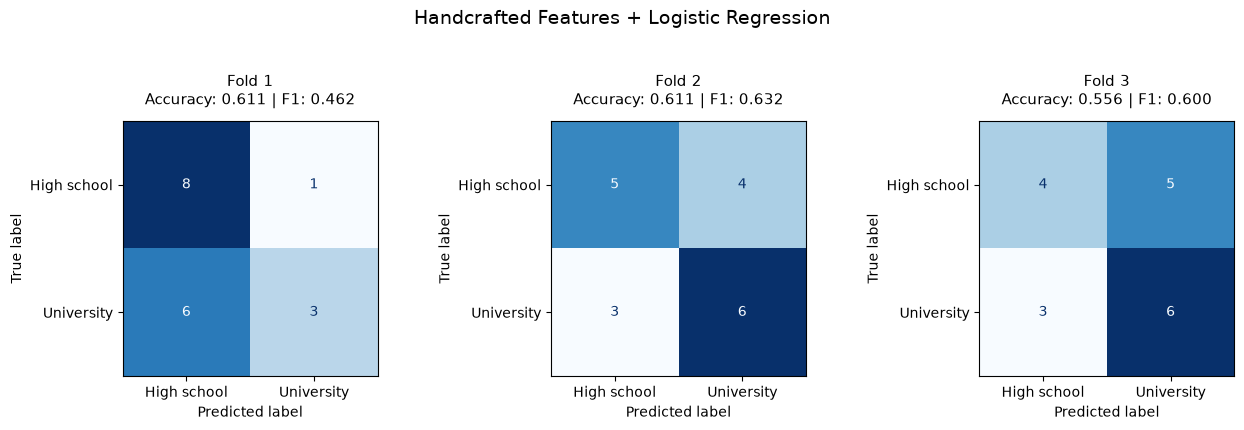

In [93]:
cv_scores = evaluate_model(
    model, X_train, y_train,
    train_df["assignment_id"], cv,
    "Handcrafted Features + Logistic Regression"
)


The model achieved a mean cross-validation accuracy of 59.3% and a mean F1 score of 0.564. This suggests that the six linguistic features contain some, but modest, predictive information.

Performance varied across validation folds. In Fold 1, the model correctly classified 8 of 9 high school passages but only 3 of 9 university passages, suggesting a tendency to predict high school. In Folds 2 and 3, it correctly identified 6 of 9 university passages but misclassified more high school passages.

Overall, the results suggest that simple linguistic measurements may capture some differences between my high school and university writing, but they are not consistently accurate, and the model's behavior depends on which assignments are used for validation. 

#### 4.4 TF-IDF + Logistic Regression

The 6 linguistic measurements may overlook differences in vocabulary and word choice that distinguish my high school and university writing. So, I'll train a second logistic regression model using Term Frequency–Inverse Document Frequency (TF-IDF), which represents each passage as a numerical vector, where each dimension corrsponds to a word in the vocabulary. TF-IDF assigns greater importance to words that appear frequently in a particular passage but are relatively uncommon across the training documents.

This representation then allows the classifier to learn from vocabulary rather than the chosen measurements. This flexibility may improve classification, although it also introduces a greater risk of overfitting given my small dataset.

I'll keep logistic regression as the classifier so I can compare the two feature representations. 

In [ ]:
# Adapted from Session 5 code
# just to illustrate how TF-IDF works, I will use the first 3 passages from the training set
texts = train_df["clean_text"].iloc[:3] # 3 passages
vectorizer = TfidfVectorizer() 
example_vectors = vectorizer.fit_transform(texts) 

# the dimensions 
print("TF-IDF matrix shape:", example_vectors.shape)
print("Vocabulary size:", len(vectorizer.vocabulary_))

# get the words corresponding to each column in the matrix
feature_names = vectorizer.get_feature_names_out()

# display the 10 words with the highest TF-IDF weights in each passage
for i in range(len(texts)):
    weights = example_vectors[i].toarray().flatten() # regular array
    word_weights = pd.DataFrame({"Word": feature_names, "TF-IDF Weight": weights}) # words and weights in dataframe
    top_words = word_weights.sort_values(by="TF-IDF Weight", ascending=False).head(10) # sort by weight
    print(f"\nPassage {i + 1}: Top 10 TF-IDF words")
    display(top_words.round(3))

TF-IDF matrix shape: (3, 284)
Vocabulary size: 284

Passage 1: Top 10 TF-IDF words


,Word,TF-IDF Weight
245,the,0.455
86,expression,0.257
151,lustre,0.257
113,humidity,0.257
23,and,0.228
118,in,0.228
56,could,0.195
81,enzyme,0.171
101,genotypes,0.171
172,of,0.152



Passage 2: Top 10 TF-IDF words


,Word,TF-IDF Weight
245,the,0.461
279,words,0.229
98,genetic,0.229
118,in,0.190
172,of,0.190
146,literary,0.184
266,variation,0.184
8,additive,0.184
192,population,0.175
203,production,0.175



Passage 3: Top 10 TF-IDF words


,Word,TF-IDF Weight
245,the,0.389
197,prion,0.239
254,to,0.212
215,research,0.180
163,my,0.180
263,us,0.180
244,that,0.141
172,of,0.141
118,in,0.141
23,and,0.137



TF-IDF + Logistic Regression


,Fold,Accuracy,F1
0,1,0.611,0.667
1,2,0.444,0.167
2,3,0.333,0.000


Mean CV accuracy: 0.463
Mean CV F1: 0.278
Accuracy SD: 0.140


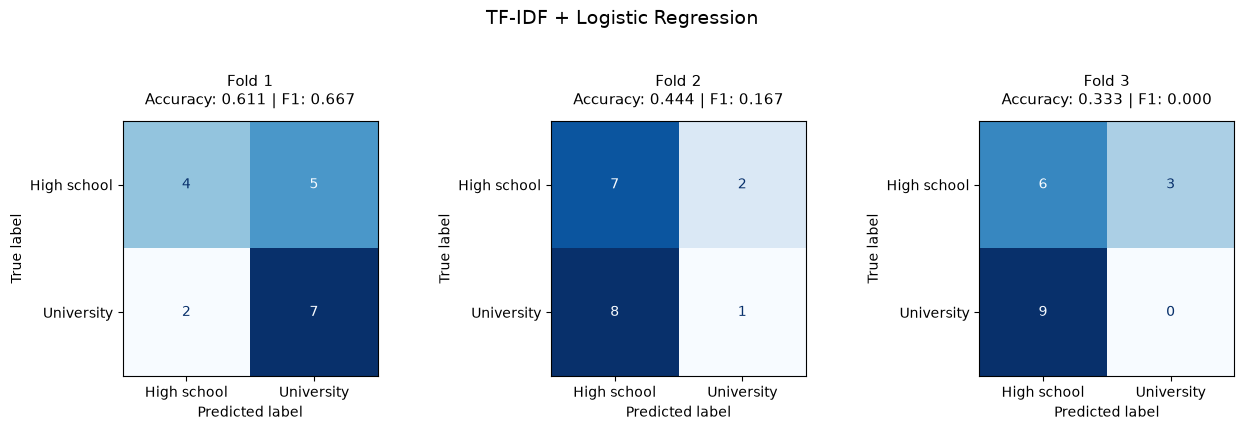

In [103]:
X_text_train = train_df["clean_text"] # use the clean text rather than the features
y_train = train_df["label"]

# pipeline that converts text into TF-IDF features and trains logistic regression
tfidf_model = make_pipeline(TfidfVectorizer(lowercase=True, ngram_range=(1, 1)), LogisticRegression(max_iter=1000))

tfidf_scores = evaluate_model(
    tfidf_model, X_text_train, y_train,
    train_df["assignment_id"], cv,
    "TF-IDF + Logistic Regression"
)

We can see the model achieved a mean cross-validation accuracy of 46.3% and a mean F1 score of 0.278, performing worse than the feature logistic regression model.

Performance also varied considerably across the folds (33.3% vs 61.1%). In one fold, the F1 score was zero, indicating that the model failed to correctly identify any university passages.

A possible explanation is that TF-IDF captures assignment-specific vocabulary rather than generalizable differences in writing style. Although I balanced the dataset across broad subjects, individual assignments still differ in terminology and content.

The handcrafted-feature model performed better despite using only six features. This suggests that the selected linguistic measurements may generalize more effectively across assignments in this dataset, although the limited sample size prevents drawing a definitive conclusion.

#### 4.5 TF-IDF + Multinomial Naive Bayes

Since the TF-IDF logistic regression model performed poorly, I'll investigate whether a different classification algorithm can better use the same word-based representation.

For this third model, I'll use Multinomial Naive Bayes, a probabilistic classifier based on Bayes' theorem. Naive Bayes assumes that features are conditionally independent given the class. Although this assumption is unrealistic for natural language, where words often appear in meaningful combinations, it simplifies probability estimation and can be effective for text classification.

Multinomial Naive Bayes directly estimates feature probabilities for each class from the training data. These estimates allow the model to determine which terms are more strongly associated with high school or university writing. I also use Laplace smoothing (alpha=1.0) to avoid assigning zero probability to features that are absent from a particular class's training samples.

By keeping the same TF-IDF vectorization and cross-validation strategy, I can isolate the effect of changing the classifier. 


TF-IDF + Multinomial Naive Bayes


,Fold,Accuracy,F1
0,1,0.500,0.4
1,2,0.389,0.0
2,3,0.278,0.0


Mean CV accuracy: 0.389
Mean CV F1: 0.133
Accuracy SD: 0.111


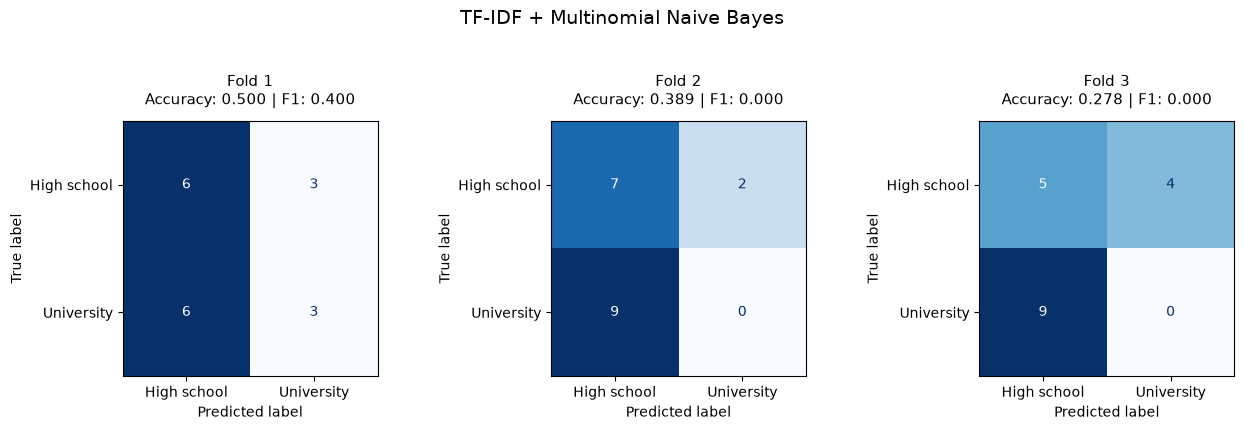

In [ ]:
# pipeline with multinomial Naive Bayes classifier
nb_model = make_pipeline(TfidfVectorizer(lowercase=True, ngram_range=(1, 1)), MultinomialNB(alpha=1.0))

nb_scores = evaluate_model(
    nb_model, X_text_train, y_train,
    train_df["assignment_id"], cv,
    "TF-IDF + Multinomial Naive Bayes"
)

I guess it keeps getting worse. This model achieved a mean cross-validation accuracy of 38.9% and a mean F1 score of 0.133, performing worse than both logistic regression models. Performance varied across folds, with accuracy decreasing from 50.0% in Fold 1 to 27.8% in Fold 3. The F1 score was zero in Folds 2 and 3, indicating that the model failed to correctly identify any university passages in those validation sets.

#### 4.6 Model Comparison

To compare the three pipelines, I summarize their mean cross-validation accuracy and F1 scores in the table below. All three models were evaluated using the same training assignments and grouped cross-validation procedure, allowing for a consistent comparison of their performance.

In [104]:

comparison = pd.DataFrame({
    "Model": ["Handcrafted Features + Logistic Regression","TF-IDF + Logistic Regression","TF-IDF + Naive Bayes"],
    "Mean Accuracy": [cv_scores["Accuracy"].mean(), tfidf_scores["Accuracy"].mean(), nb_scores["Accuracy"].mean()],
    "Mean F1": [cv_scores["F1"].mean(), tfidf_scores["F1"].mean(), nb_scores["F1"].mean()]
})

display(comparison.round(3))

,Model,Mean Accuracy,Mean F1
0,Handcrafted Features + Logistic Regression,0.593,0.564
1,TF-IDF + Logistic Regression,0.463,0.278
2,TF-IDF + Naive Bayes,0.389,0.133


Comparing the three models reveals two interesting findings. First, the handcrafted-feature logistic regression model achieved the highest mean accuracy (59.3%) and F1 score (0.564), suggesting that broad stylistic measurements may provide more generalizable information than individual vocabulary terms in this dataset. Second, replacing logistic regression with Naive Bayes did not improve TF-IDF classification, suggesting that the weak performance of the word-based representation was not specific to logistic regression.

Nevertheless, the dataset contains only 22 independent assignments, and these results depend on the chosen model configurations and validation splits. Therefore, the findings should be interpreted as preliminary rather than definitive evidence that linguistic features are more informative than vocabulary.

#### 4.8 Final Model Evaluation

Based on the performance, logistic regression with six handcrafted linguistic features is so far my selected model. To estimate how well this model generalizes to previously unseen assignments, I'll train it on all 18 training assignments and evaluate it on the four assignments reserved for testing. 

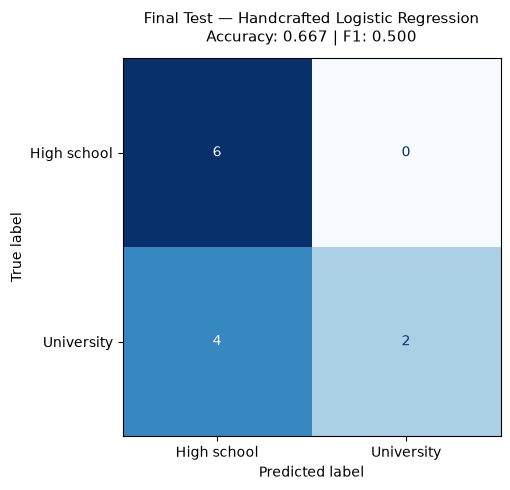

In [98]:
# prepare the final test data using the same six linguistic features
X_test = test_df[features]
y_test = test_df["label"]

# train the selected model on all 18 training assignments
model.fit(X_train, y_train)

# predict the labels of the 12 previously unseen test passages
test_predictions = model.predict(X_test)

fig, ax = plt.subplots(figsize=(6, 5))

plot_confusion_matrix(
    y_test, test_predictions, ax,
    "Final Test — Handcrafted Logistic Regression"
)

plt.tight_layout()
plt.show()


**Final Test Results**

The selected model achieved 66.7% accuracy and an F1 score of 0.500 on the test set, correctly classifying 8 of 12 passages.

Because the classes are equally represented, a classifier that always predicts the same educational level would achieve 50% accuracy on this test set. My model exceeds this baseline by 16.7 percentage points, equivalent to two additional correct predictions.

However, the confusion matrix suggests that the model was more successful at identifying high school writing than university writing, frequently classifying university passages as high school.

Interestingly, the final test accuracy was higher than the mean cross-validation accuracy (59.3%). This may reflect the fact that the final model was trained on more assignments than the models in individual validation folds.  

Also relevant to note that the test set contained only four independent assignments, making the performance estimate sensitive to the particular assignments selected. 

So my writing may have changed in measurable ways, but maybe not 🤷‍♀️. All that tuition money...


### 5. Limitations, and Future Directions

The primary limitation is the small dataset, consisting of 66 passages from only 22 independent assignments. Although splitting by assignment prevents passages from the same document from appearing in both training and validation sets, the small number of independent documents makes performance estimates sensitive to the particular assignments selected.

Furthermore, the model predicts educational period rather than writing quality. Even though I balanced the dataset across broad subject categories, differences in assignment requirements, vocabulary, or writing conventions could influence predictions independently of actual improvements in writing ability.

Moreover the linguistic features are a relatively narrow representation of writing style. While word length, vocabulary diversity, sentence length, and punctuation frequency are interpretable, they do not directly measure how ideas are organized, how arguments are developed, or how effectively language is used. Similarly, TF-IDF represents individual words without capturing much of their meaning or surrounding context.

In the future, I would explore additional measures of writing, including readability scores such as Flesch Reading Ease, syntactic complexity through subordinate clauses and sentence structure, and lexical sophistication through the use of less common or more advanced vocabulary. These features might provide a more comprehensive picture of how my writing has changed.

### 6. References

- Readable. (n.d.). Flesch Reading Ease and Flesch-Kincaid Grade Level. https://readable.com/readability/flesch-reading-ease-flesch-kincaid-grade-level/
- Python Software Foundation. (n.d.). *re — Regular expression operations*. https://docs.python.org/3/library/re.html
- Python Software Foundation. (n.d.). *unicodedata — Unicode database*. https://docs.python.org/3/library/unicodedata.html
- Scikit-learn developers. (n.d.). *Cross-validation: Evaluating estimator performance*. https://scikit-learn.org/stable/modules/cross_validation.html
- Scikit-learn developers. (n.d.). *Pipeline*. https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html
- Scikit-learn developers. (n.d.). *StandardScaler*. https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html
- Scikit-learn developers. (n.d.). *LogisticRegression*. https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html
- Scikit-learn developers. (n.d.). *TfidfVectorizer*. https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html
- Scikit-learn developers. (n.d.). *Multinomial Naive Bayes*. https://scikit-learn.org/stable/modules/naive_bayes.html#multinomial-naive-bayes
- Scikit-learn developers. (n.d.). *Classification metrics*. https://scikit-learn.org/stable/modules/model_evaluation.html#classification-metrics
- Scikit-learn developers. (n.d.). *DummyClassifier*. https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyClassifier.html

**AI Statement**: AI tools were used throughout this project for brainstorming, answering general questions, and providing some coding assistance. I used GitHub Copilot in VS Code for minor code fixes. For instance, I initially added imports throughout the notebook as I needed them, but later asked Copilot to consolidate them at the beginning to improve organization. I also used ChatGPT to clarify concepts and ask general questions https://chatgpt.com/share/6ad53742-f560-83ed-bbf3-a8e59ace6a69 

During the initial brainstorming stage, I also discussed potential project ideas with LLMs. I was originally leaning toward analyzing my personal Spotify listening data, which I had already downloaded, but ultimately decided this could be more fun. However, maybe I'll change my direction in the future assignments. 